# 07 Validation against PTAI-2022
Checks whether the demand-gap score agrees with an **independent** measure: the Public Transport Accessibility Indicators (Verduzco Torres & McArthur, 2024), which count destinations reachable by public transport in N minutes.

**Expected relationships**
- Gap score vs jobs / GPs / supermarkets reachable (higher = better access): **negative**.
- Gap score vs minutes to the nearest GP / supermarket / hospital (higher = worse access): **positive**.

**Caveats (state in the report):** PTAI covers all public transport, not only buses, and measures reaching destinations, not provision against need, so only a moderate relationship is expected. PTAI is for a Tuesday in November 2021 on **2011** LSOA codes; our timetable is from 2026 on **2021** codes. LSOAs whose codes changed between censuses do not match and are dropped (match rate shown).
Run from `notebooks/`.

In [8]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
CLEAN = Path("../data/clean")
P = Path("../data/raw/ptai_2022/accessibility_indicators_gb/accessibility")
df = pd.read_parquet(CLEAN / "lsoa_score.parquet")
print(len(df), "England LSOAs (2021 codes)")

33755 England LSOAs (2021 codes)


## 1. Load PTAI (public transport files) and join on LSOA code

In [9]:
files = {
    "employment": ("employment/access_employment_pt.csv", ["employment_pct_30", "employment_pct_45", "employment_pct_60"]),
    "gp": ("gp/access_gp_pt.csv", ["gp_pct_30", "nearest_gp"]),
    "supermarket": ("supermarket/access_supermarkets_pt.csv", ["supermarket_pct_30", "nearest_supermarket"]),
    "hospital": ("hospitals/access_hospital_pt.csv", ["nearest_hosp"]),
}
ptai = None
for name, (f, cols) in files.items():
    t = pd.read_csv(P / f, usecols=["geo_code"] + cols)
    ptai = t if ptai is None else ptai.merge(t, on="geo_code", how="outer")
ptai = ptai[ptai.geo_code.str.startswith("E01")]
m = df.merge(ptai, left_on="LSOA21CD", right_on="geo_code", how="inner")
print(f"PTAI England LSOAs: {len(ptai):,} | matched to our 2021 LSOAs: {len(m):,} ({len(m)/len(df):.1%} of ours)")

PTAI England LSOAs: 32,844 | matched to our 2021 LSOAs: 31,810 (94.2% of ours)


## 2. Rank correlations (Spearman)

In [10]:
measures = {
    "employment_pct_45": "Jobs reachable in 45 min (share of GB)",
    "employment_pct_30": "Jobs reachable in 30 min",
    "gp_pct_30": "GPs reachable in 30 min",
    "supermarket_pct_30": "Supermarkets reachable in 30 min",
    "nearest_gp": "Minutes to nearest GP",
    "nearest_supermarket": "Minutes to nearest supermarket",
    "nearest_hosp": "Minutes to nearest hospital",
}
rows = []
for col, label in measures.items():
    r = {"PTAI measure": label, "expected sign": "-" if "pct" in col else "+", "n": m[col].notna().sum()}
    for grp, g in [("All", m), ("Urban", m[m.Urban_rura == "Urban"]), ("Rural", m[m.Urban_rura == "Rural"])]:
        r[f"rho {grp}"] = g["gap_score"].corr(g[col], method="spearman")
    rows.append(r)
val = pd.DataFrame(rows); val.round(3)

,PTAI measure,expected sign,n,rho All,rho Urban,rho Rural
0,Jobs reachable in 45 min (share of GB),-,31810,-0.133,-0.027,-0.416
1,Jobs reachable in 30 min,-,31810,-0.105,0.002,-0.317
2,GPs reachable in 30 min,-,31810,-0.068,0.042,-0.219
3,Supermarkets reachable in 30 min,-,31810,-0.090,0.013,-0.247
4,Minutes to nearest GP,+,31775,0.015,-0.064,0.233
5,Minutes to nearest supermarket,+,31720,0.078,-0.006,0.309
6,Minutes to nearest hospital,+,31546,0.086,-0.000,0.301


## 3. Do the biggest-gap areas have worse PTAI access?

In [11]:
cmp = m.groupby("gap_top10")[["employment_pct_45", "gp_pct_30", "supermarket_pct_30", "nearest_gp", "nearest_supermarket"]].median().round(3)
cmp.index = ["Other 90%", "Top 10% gap"]
cmp

,employment_pct_45,gp_pct_30,supermarket_pct_30,nearest_gp,nearest_supermarket
Other 90%,0.168,0.051,0.062,13.0,14.0
Top 10% gap,0.186,0.076,0.077,11.0,14.0


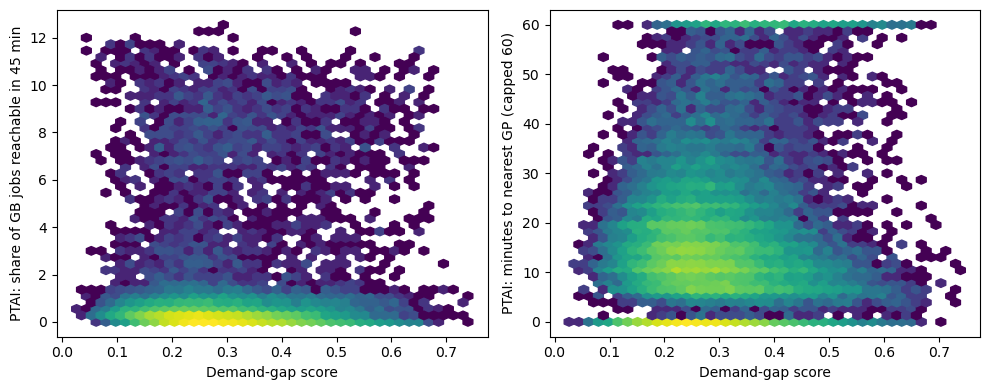

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].hexbin(m["gap_score"], m["employment_pct_45"], gridsize=40, bins="log", cmap="viridis", mincnt=1)
ax[0].set_xlabel("Demand-gap score"); ax[0].set_ylabel("PTAI: share of GB jobs reachable in 45 min")
ax[1].hexbin(m["gap_score"], m["nearest_gp"].clip(upper=60), gridsize=40, bins="log", cmap="viridis", mincnt=1)
ax[1].set_xlabel("Demand-gap score"); ax[1].set_ylabel("PTAI: minutes to nearest GP (capped 60)")
plt.tight_layout()

## 4. Does the result depend on the weights?
Recompute the score with the supply (frequency) part removed and with each part alone, then correlate with jobs reachable in 45 min.

In [13]:
def norm01(s):
    a, b = s.quantile([0.01, 0.99]); return (s.clip(a, b) - a) / (b - a)
comp = pd.DataFrame({
    "access": norm01(m["dist_nearest_stop_m"]), "supply": norm01(-np.log1p(m["freq_per_1000"])),
    "density": norm01(m["pop_density"]), "deprivation": norm01(m["imd_score"])})
rows = [{"component": c, "rho vs jobs in 45 min": comp[c].corr(m["employment_pct_45"], method="spearman")} for c in comp]
rows.append({"component": "combined score", "rho vs jobs in 45 min": m["gap_score"].corr(m["employment_pct_45"], method="spearman")})
pd.DataFrame(rows).round(3)

,component,rho vs jobs in 45 min
0,access,-0.353
1,supply,-0.332
2,density,0.689
3,deprivation,0.241
4,combined score,-0.133


## 5. Save

In [14]:
val.to_csv(CLEAN / "validation_ptai.csv", index=False)
print("saved")

The history saving thread hit an unexpected error (OperationalError('database is locked')).History will not be written to the database.
saved
